# Lippold et al. (2024) — Atlantic Sediment Core Analysis

**Dataset:** PANGAEA.971789  
**DOI:** https://doi.org/10.1594/PANGAEA.971789

**Description:** 231Pa/230Th ratios and related radioisotope
concentrations from eleven Atlantic sediment cores during the Holocene.

In [2]:
import pandas as pd
from pathlib import Path
from io import StringIO

file_path = Path("/Users/farabiisa/Desktop/Thesis_Work/02_Notebooks/Atlantic sediment cores/Scheen-etal_2024.tab")

text = file_path.read_text(encoding="utf-8-sig")
table_text = text.split("*/", 1)[-1].lstrip()

df = pd.read_csv(StringIO(table_text), sep="\t")

print("Rows:", len(df))
print("Columns:", df.columns.tolist())
display(df.head())

Rows: 44
Columns: ['Event', 'Core', 'H', 'Depth sed [m]', 'Depth top [m]', 'Depth bot [m]', 'Age [ka BP]', 'Reference', '231Pa/230Th xs0', '231Pa/230Th ex,0 e rel [%]', '231Pa [dpm/g]', '231Pa e rel [%]', '230Th [dpm/g]', '230Th e rel [%]', '232Th [dpm/g]', '232Th e rel [%]', '238U [dpm/g]', '238U e rel [%]']


,Event,Core,H,Depth sed [m],Depth top [m],Depth bot [m],Age [ka BP],Reference,231Pa/230Th xs0,"231Pa/230Th ex,0 e rel [%]",231Pa [dpm/g],231Pa e rel [%],230Th [dpm/g],230Th e rel [%],232Th [dpm/g],232Th e rel [%],238U [dpm/g],238U e rel [%]
0,AII107-117GGC,AII107-09 117GGC,NaN,0.0350,0.030,0.040,5.6,"Jones, G.A., Johnson, D.A., Curry, W.B. (1984)...",0.044,2.0,0.35,1.6,8.61,1.1,0.46,0.8,0.34,0.5
1,AII107-117GGC,AII107-09 117GGC,NaN,0.0450,0.040,0.050,6.1,"Jones, G.A., Johnson, D.A., Curry, W.B. (1984)...",0.041,1.7,0.37,0.9,9.54,1.3,0.55,1.0,0.39,0.5
2,AII107-117GGC,AII107-09 117GGC,NaN,0.0575,0.055,0.060,6.9,"Jones, G.A., Johnson, D.A., Curry, W.B. (1984)...",0.044,2.7,0.38,0.8,9.28,2.5,0.52,3.3,0.37,0.5
3,AII107-117GGC,AII107-09 117GGC,NaN,0.0725,0.070,0.075,7.7,"Jones, G.A., Johnson, D.A., Curry, W.B. (1984)...",0.043,1.7,0.34,0.8,8.72,1.5,0.50,1.2,0.35,0.5
4,GeoB18530-1,GeoB18530-1,NaN,0.0200,0.010,0.030,0.0,"Max, L., Nürnberg, D., Chiessi, C.M., Lenz, M....",0.080,5.3,0.14,1.8,2.12,2.5,1.95,1.2,1.21,0.5


Checking the number of sediment cores

In [3]:
print("Unique events:", df["Event"].nunique())
print("Unique cores:", df["Core"].nunique())

core_summary = (
    df.groupby(["Event", "Core"], dropna=False)
    .agg(
        samples=("Depth sed [m]", "size"),
        min_age_ka=("Age [ka BP]", "min"),
        max_age_ka=("Age [ka BP]", "max"),
        min_depth_m=("Depth sed [m]", "min"),
        max_depth_m=("Depth sed [m]", "max"),
    )
    .reset_index()
)

display(core_summary)

Unique events: 12
Unique cores: 11


,Event,Core,samples,min_age_ka,max_age_ka,min_depth_m,max_depth_m
0,162-983A,ODP 983,2,3.0,6.0,0.110,0.8100
1,306-U1313B,IODP 1313,2,5.3,6.6,0.035,0.0750
2,306-U1313C,IODP 1313,4,2.1,5.5,0.010,0.1550
3,AII107-117GGC,AII107-09 117GGC,4,5.6,7.7,0.035,0.0725
4,GeoB18530-1,GeoB18530-1,4,0.0,7.6,0.020,1.5180
5,KNR159-17,KNR159-5 17JPC,1,7.1,7.1,0.015,0.0150
6,KNR159-33,KNR159-5 33GGC,6,1.6,8.0,0.035,0.2150
7,KNR159-5-22GGC,KNR159-5 22GGC,1,7.3,7.3,0.005,0.0050
8,KNR159-5-30GGC,KNR159-5 30GGC,5,2.7,7.4,0.055,0.1450
9,MSM58_669-2,MSM58-13-2,6,2.7,7.0,0.015,0.2550


Checking missing measurements

In [4]:
required_columns = [
    "230Th [dpm/g]",
    "232Th [dpm/g]",
    "238U [dpm/g]"
]

print("Missing values by isotope:")
print(df[required_columns].isna().sum())

complete_samples = df.dropna(subset=required_columns)

print("\nTotal samples:", len(df))
print("Complete isotope samples:", len(complete_samples))
print("Incomplete samples:", len(df) - len(complete_samples))

Missing values by isotope:
230Th [dpm/g]    0
232Th [dpm/g]    0
238U [dpm/g]     0
dtype: int64

Total samples: 44
Complete isotope samples: 44
Incomplete samples: 0


In [5]:
quality_summary = (
    df.assign(
        has_all_isotopes=df[required_columns].notna().all(axis=1)
    )
    .groupby(["Event", "Core"], dropna=False)
    .agg(
        total_samples=("Event", "size"),
        complete_samples=("has_all_isotopes", "sum")
    )
    .reset_index()
)

quality_summary["completeness_percent"] = (
    quality_summary["complete_samples"]
    / quality_summary["total_samples"]
    * 100
).round(1)

display(quality_summary)

,Event,Core,total_samples,complete_samples,completeness_percent
0,162-983A,ODP 983,2,2,100.0
1,306-U1313B,IODP 1313,2,2,100.0
2,306-U1313C,IODP 1313,4,4,100.0
3,AII107-117GGC,AII107-09 117GGC,4,4,100.0
4,GeoB18530-1,GeoB18530-1,4,4,100.0
5,KNR159-17,KNR159-5 17JPC,1,1,100.0
6,KNR159-33,KNR159-5 33GGC,6,6,100.0
7,KNR159-5-22GGC,KNR159-5 22GGC,1,1,100.0
8,KNR159-5-30GGC,KNR159-5 30GGC,5,5,100.0
9,MSM58_669-2,MSM58-13-2,6,6,100.0


## Data Quality Control
### Validating sample depths, ages, and uncertainties

In [6]:
# Checking missing values in the remaining important fields
qc_columns = [
    "Depth sed [m]",
    "Depth top [m]",
    "Depth bot [m]",
    "Age [ka BP]",
    "230Th e rel [%]",
    "232Th e rel [%]",
    "238U e rel [%]"
]

print("Missing values:")
print(df[qc_columns].isna().sum())

# Checking invalid sample intervals
invalid_depths = df[
    df["Depth top [m]"].notna()
    & df["Depth bot [m]"].notna()
    & (
        (df["Depth top [m]"] > df["Depth bot [m]"])
        | (df["Depth sed [m]"] < df["Depth top [m]"])
        | (df["Depth sed [m]"] > df["Depth bot [m]"])
    )
]

print("\nInvalid depth intervals:", len(invalid_depths))

# Checking negative ages
print("Negative ages:", (df["Age [ka BP]"] < 0).sum())

# Check invalid relative uncertainties
error_columns = [
    "230Th e rel [%]",
    "232Th e rel [%]",
    "238U e rel [%]"
]

for col in error_columns:
    print(f"{col}: {(df[col] < 0).sum()} negative errors")

Missing values:
Depth sed [m]      0
Depth top [m]      0
Depth bot [m]      0
Age [ka BP]        0
230Th e rel [%]    0
232Th e rel [%]    0
238U e rel [%]     0
dtype: int64

Invalid depth intervals: 0
Negative ages: 0
230Th e rel [%]: 0 negative errors
232Th e rel [%]: 0 negative errors
238U e rel [%]: 0 negative errors


Extracting site metadata from the PANGAEA file

In [7]:
metadata_text = text.split("*/", 1)[0]

print(metadata_text[:12000])

/* DATA DESCRIPTION:
Citation:	Lippold, Jörg; Scheen, Jeemijn; Pöppelmeier, Frerk; Süfke, Finn; Stocker, Thomas F; Regelous, Marcel (2024): 231Pa/230Th (Pa/Th) and related radioisotope concentrations from eleven Atlantic sediment cores for the Holocene [dataset]. PANGAEA, https://doi.org/10.1594/PANGAEA.971789
Abstract:	231Pa/230Th and related radioisotope concentrations from eleven Atlantic sediment cores for the Holocene. The concentrations of sedimentary 231Pa, 238U, 230Th, and 232Th were measured using ID-ICP-MS in a co-operation between Heidelberg University and GeoZentrum Nordbayern, FAU Erlangen‐Nürnberg.
Keyword(s):	231Pa/230Th; Atlantic; Holocene; Pa/Th; Protactinium; Thorium; Uranium
Supplement to:	Scheen, Jeemijn; Lippold, Jörg; Pöppelmeier, Frerk; Süfke, Finn; Stocker, Thomas F (2025): Promising Regions for Detecting the Overturning Circulation in Atlantic 231 Pa/ 230 Th: A Model-Data Comparison. Paleoceanography and Paleoclimatology, 40(3), e2024PA004869, https://doi.org/1

In [8]:
import re

# Extracting only the Event(s) section
events_section = metadata_text.split("Event(s):", 1)[1].split(
    "Parameter(s):", 1
)[0]

event_pattern = re.compile(
    r"(?:^|\n|\t)([A-Za-z0-9][A-Za-z0-9_-]*)"
    r"(?:\s+\([^)]*\))?\s*\*\s*LATITUDE:\s*"
    r"(-?\d+(?:\.\d+)?)\s*\*\s*LONGITUDE:\s*"
    r"(-?\d+(?:\.\d+)?)"
    r".*?\*\s*ELEVATION:\s*(-?\d+(?:\.\d+)?)\s*m",
    re.DOTALL
)

records = []

for match in event_pattern.finditer(events_section):
    event, lat, lon, elevation = match.groups()

    records.append({
        "event_id": event,
        "latitude": float(lat),
        "longitude": float(lon),
        "elevation_m": float(elevation),
        "water_depth_m": -float(elevation),
        "dataset_doi": "10.1594/PANGAEA.971789"
    })

sites_df = pd.DataFrame(records)

display(sites_df)
print("Extracted events:", len(sites_df))

,event_id,latitude,longitude,elevation_m,water_depth_m,dataset_doi
0,162-983A,60.403300,-23.640600,-1983.0,1983.0,10.1594/PANGAEA.971789
1,306-U1313B,41.000023,-32.957300,-3413.5,3413.5,10.1594/PANGAEA.971789
2,306-U1313C,41.000022,-32.957010,-3412.7,3412.7,10.1594/PANGAEA.971789
3,AII107-117GGC,-30.840000,-38.240000,-3282.0,3282.0,10.1594/PANGAEA.971789
4,GeoB18530-1,42.839500,-49.234833,-1888.0,1888.0,10.1594/PANGAEA.971789
5,KNR159-5-22GGC,-29.783000,-43.583000,-3924.0,3924.0,10.1594/PANGAEA.971789
6,KNR159-5-30GGC,-28.133000,-46.067000,-2500.0,2500.0,10.1594/PANGAEA.971789
7,KNR159-17,-27.697170,-46.494000,-1627.0,1627.0,10.1594/PANGAEA.971789
8,KNR159-33,-27.555170,-46.074670,-2082.0,2082.0,10.1594/PANGAEA.971789
9,MSM58_669-2,40.400670,-31.079670,-2103.4,2103.4,10.1594/PANGAEA.971789


Extracted events: 12


In [9]:
core_info = (
    df.groupby("Event")
    .agg(
        core_name=("Core", "first"),
        sample_count=("Core", "size")
    )
    .reset_index()
    .rename(columns={"Event": "event_id"})
)

sites_df = sites_df.merge(
    core_info,
    on="event_id",
    how="outer",
    validate="one_to_one"
)

sites_df = sites_df[
    [
        "event_id",
        "core_name",
        "latitude",
        "longitude",
        "elevation_m",
        "water_depth_m",
        "sample_count",
        "dataset_doi"
    ]
]

display(sites_df)

,event_id,core_name,latitude,longitude,elevation_m,water_depth_m,sample_count,dataset_doi
0,162-983A,ODP 983,60.403300,-23.640600,-1983.0,1983.0,2,10.1594/PANGAEA.971789
1,306-U1313B,IODP 1313,41.000023,-32.957300,-3413.5,3413.5,2,10.1594/PANGAEA.971789
2,306-U1313C,IODP 1313,41.000022,-32.957010,-3412.7,3412.7,4,10.1594/PANGAEA.971789
3,AII107-117GGC,AII107-09 117GGC,-30.840000,-38.240000,-3282.0,3282.0,4,10.1594/PANGAEA.971789
4,GeoB18530-1,GeoB18530-1,42.839500,-49.234833,-1888.0,1888.0,4,10.1594/PANGAEA.971789
5,KNR159-17,KNR159-5 17JPC,-27.697170,-46.494000,-1627.0,1627.0,1,10.1594/PANGAEA.971789
6,KNR159-33,KNR159-5 33GGC,-27.555170,-46.074670,-2082.0,2082.0,6,10.1594/PANGAEA.971789
7,KNR159-5-22GGC,KNR159-5 22GGC,-29.783000,-43.583000,-3924.0,3924.0,1,10.1594/PANGAEA.971789
8,KNR159-5-30GGC,KNR159-5 30GGC,-28.133000,-46.067000,-2500.0,2500.0,5,10.1594/PANGAEA.971789
9,MSM58_669-2,MSM58-13-2,40.400670,-31.079670,-2103.4,2103.4,6,10.1594/PANGAEA.971789


In [10]:
print("Total events:", df["Event"].nunique())
print("Metadata records:", len(sites_df))

print("Missing coordinates:")
print(sites_df[["latitude", "longitude"]].isna().sum())

print("Invalid latitude:", (~sites_df["latitude"].between(-90, 90)).sum())
print("Invalid longitude:", (~sites_df["longitude"].between(-180, 180)).sum())

print("Missing water depth:", sites_df["water_depth_m"].isna().sum())
print("Non-positive water depth:", (sites_df["water_depth_m"] <= 0).sum())

Total events: 12
Metadata records: 12
Missing coordinates:
latitude     0
longitude    0
dtype: int64
Invalid latitude: 0
Invalid longitude: 0
Missing water depth: 0
Non-positive water depth: 0


In [11]:
output_dir = Path("/Users/farabiisa/Desktop/Thesis_Work/03_Data/Processed")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "lippold_2024_sites.csv"

sites_df.to_csv(output_file, index=False)

print("Saved:", output_file.resolve())

Saved: /Users/farabiisa/Desktop/Thesis_Work/03_Data/Processed/lippold_2024_sites.csv


Standardizing D-sample measurements

In [12]:
column_mapping = {
    "Event": "event_id",
    "Core": "core_name",
    "H": "hole",
    "Depth sed [m]": "depth_m",
    "Depth top [m]": "depth_top_m",
    "Depth bot [m]": "depth_bottom_m",
    "Age [ka BP]": "age_ka_bp",
    "Reference": "age_model_reference",
    "230Th [dpm/g]": "th230_dpm_g",
    "230Th e rel [%]": "th230_error_rel_pct",
    "232Th [dpm/g]": "th232_dpm_g",
    "232Th e rel [%]": "th232_error_rel_pct",
    "238U [dpm/g]": "u238_dpm_g",
    "238U e rel [%]": "u238_error_rel_pct",
    "231Pa [dpm/g]": "pa231_dpm_g",
    "231Pa e rel [%]": "pa231_error_rel_pct",
    "231Pa/230Th xs0": "pa231_th230_xs0_ratio",
    "231Pa/230Th ex,0 e rel [%]": "pa231_th230_xs0_error_rel_pct"
}

d_samples_df = df.rename(columns=column_mapping).copy()

d_samples_df["dataset_doi"] = "10.1594/PANGAEA.971789"
d_samples_df["source_dataset"] = "Lippold et al. (2024)"

display(d_samples_df.head())
print("Samples:", len(d_samples_df))
print("Columns:", len(d_samples_df.columns))

,event_id,core_name,hole,depth_m,depth_top_m,depth_bottom_m,age_ka_bp,age_model_reference,pa231_th230_xs0_ratio,pa231_th230_xs0_error_rel_pct,pa231_dpm_g,pa231_error_rel_pct,th230_dpm_g,th230_error_rel_pct,th232_dpm_g,th232_error_rel_pct,u238_dpm_g,u238_error_rel_pct,dataset_doi,source_dataset
0,AII107-117GGC,AII107-09 117GGC,NaN,0.0350,0.030,0.040,5.6,"Jones, G.A., Johnson, D.A., Curry, W.B. (1984)...",0.044,2.0,0.35,1.6,8.61,1.1,0.46,0.8,0.34,0.5,10.1594/PANGAEA.971789,Lippold et al. (2024)
1,AII107-117GGC,AII107-09 117GGC,NaN,0.0450,0.040,0.050,6.1,"Jones, G.A., Johnson, D.A., Curry, W.B. (1984)...",0.041,1.7,0.37,0.9,9.54,1.3,0.55,1.0,0.39,0.5,10.1594/PANGAEA.971789,Lippold et al. (2024)
2,AII107-117GGC,AII107-09 117GGC,NaN,0.0575,0.055,0.060,6.9,"Jones, G.A., Johnson, D.A., Curry, W.B. (1984)...",0.044,2.7,0.38,0.8,9.28,2.5,0.52,3.3,0.37,0.5,10.1594/PANGAEA.971789,Lippold et al. (2024)
3,AII107-117GGC,AII107-09 117GGC,NaN,0.0725,0.070,0.075,7.7,"Jones, G.A., Johnson, D.A., Curry, W.B. (1984)...",0.043,1.7,0.34,0.8,8.72,1.5,0.50,1.2,0.35,0.5,10.1594/PANGAEA.971789,Lippold et al. (2024)
4,GeoB18530-1,GeoB18530-1,NaN,0.0200,0.010,0.030,0.0,"Max, L., Nürnberg, D., Chiessi, C.M., Lenz, M....",0.080,5.3,0.14,1.8,2.12,2.5,1.95,1.2,1.21,0.5,10.1594/PANGAEA.971789,Lippold et al. (2024)


Samples: 44
Columns: 20


In [13]:
d_samples_df["sample_id"] = [
    f"LIPPOLD2024_{i:04d}"
    for i in range(1, len(d_samples_df) + 1)
]

cols = ["sample_id"] + [
    col for col in d_samples_df.columns
    if col != "sample_id"
]

d_samples_df = d_samples_df[cols]

display(d_samples_df[
    ["sample_id", "event_id", "depth_m", "age_ka_bp", "th230_dpm_g", "th232_dpm_g"]
].head())

,sample_id,event_id,depth_m,age_ka_bp,th230_dpm_g,th232_dpm_g
0,LIPPOLD2024_0001,AII107-117GGC,0.0350,5.6,8.61,0.46
1,LIPPOLD2024_0002,AII107-117GGC,0.0450,6.1,9.54,0.55
2,LIPPOLD2024_0003,AII107-117GGC,0.0575,6.9,9.28,0.52
3,LIPPOLD2024_0004,AII107-117GGC,0.0725,7.7,8.72,0.50
4,LIPPOLD2024_0005,GeoB18530-1,0.0200,0.0,2.12,1.95


In [15]:
unknown_events = set(d_samples_df["event_id"]) - set(sites_df["event_id"])

print("Unknown events:", unknown_events)

# Check unique sample identifiers
print("Duplicate sample IDs:", d_samples_df["sample_id"].duplicated().sum())

# Check total sample counts
print("D-samples:", len(d_samples_df))
print("Samples recorded in sites table:", sites_df["sample_count"].sum())

assert not unknown_events
assert d_samples_df["sample_id"].is_unique

assert len(d_samples_df) == sites_df["sample_count"].sum()

Unknown events: set()
Duplicate sample IDs: 0
D-samples: 44
Samples recorded in sites table: 44


In [16]:
output_file = output_dir / "lippold_2024_d_samples.csv"

d_samples_df.to_csv(output_file, index=False)

print("Saved:", output_file.resolve())

Saved: /Users/farabiisa/Desktop/Thesis_Work/03_Data/Processed/lippold_2024_d_samples.csv


Age-depth consistency checks

In [17]:
age_depth_flags = []

for event_id, group in d_samples_df.groupby("event_id"):
    group = group.sort_values("depth_m")

    if len(group) < 2:
        continue

    age_difference = group["age_ka_bp"].diff()

    suspicious = group[age_difference < 0]

    for _, row in suspicious.iterrows():
        age_depth_flags.append({
            "event_id": event_id,
            "sample_id": row["sample_id"],
            "depth_m": row["depth_m"],
            "age_ka_bp": row["age_ka_bp"],
            "issue": "Age decreases with increasing depth"
        })

age_depth_qc = pd.DataFrame(age_depth_flags)

print("Suspicious age-depth records:", len(age_depth_qc))
display(age_depth_qc)

Suspicious age-depth records: 1


,event_id,sample_id,depth_m,age_ka_bp,issue
0,162-983A,LIPPOLD2024_0037,0.81,3.0,Age decreases with increasing depth


In [18]:
# Created a copy of the standardized dataset
d_samples_qc = d_samples_df.copy()

# Default status
d_samples_qc["age_depth_qc"] = "pass"

# Flag event for review
d_samples_qc.loc[
    d_samples_qc["event_id"] == "162-983A",
    "age_depth_qc"
] = "review_depth_scale"

display(
    d_samples_qc.loc[
        d_samples_qc["event_id"] == "162-983A",
        [
            "sample_id",
            "event_id",
            "hole",
            "depth_m",
            "age_ka_bp",
            "age_depth_qc"
        ]
    ]
)

,sample_id,event_id,hole,depth_m,age_ka_bp,age_depth_qc
36,LIPPOLD2024_0037,162-983A,AH1W,0.81,3.0,review_depth_scale
37,LIPPOLD2024_0038,162-983A,AH2W,0.11,6.0,review_depth_scale


In [19]:
qc_file = output_dir / "lippold_2024_d_samples_qc.csv"

d_samples_qc.to_csv(qc_file, index=False)

print("Saved:", qc_file.resolve())

Saved: /Users/farabiisa/Desktop/Thesis_Work/03_Data/Processed/lippold_2024_d_samples_qc.csv


# Visualizing

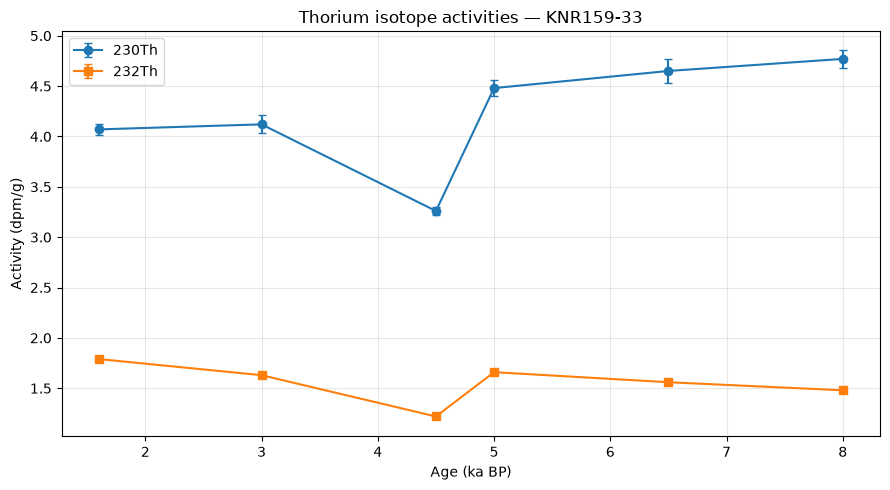

In [20]:
import matplotlib.pyplot as plt

event_id = "KNR159-33"

core_data = (
    d_samples_qc[
        d_samples_qc["event_id"] == event_id
    ]
    .sort_values("age_ka_bp")
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.errorbar(
    core_data["age_ka_bp"],
    core_data["th230_dpm_g"],
    yerr=(
        core_data["th230_dpm_g"]
        * core_data["th230_error_rel_pct"] / 100
    ),
    fmt="o-",
    capsize=3,
    label="230Th"
)

ax.errorbar(
    core_data["age_ka_bp"],
    core_data["th232_dpm_g"],
    yerr=(
        core_data["th232_dpm_g"]
        * core_data["th232_error_rel_pct"] / 100
    ),
    fmt="s-",
    capsize=3,
    label="232Th"
)

ax.set_xlabel("Age (ka BP)")
ax.set_ylabel("Activity (dpm/g)")
ax.set_title(f"Thorium isotope activities — {event_id}")
ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

/opt/anaconda3/envs/thesis-work/lib/python3.11/site-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_land.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)
/opt/anaconda3/envs/thesis-work/lib/python3.11/site-packages/cartopy/io/__init__.py:242: DownloadWarning: Downloading: https://naturalearth.s3.amazonaws.com/110m_physical/ne_110m_ocean.zip
  warnings.warn(f'Downloading: {url}', DownloadWarning)


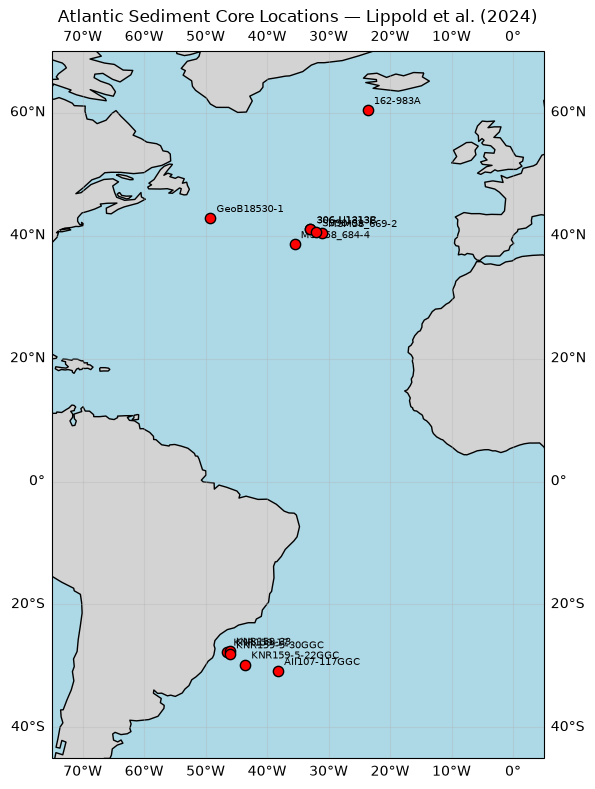

In [23]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

fig = plt.figure(figsize=(10, 8))

ax = plt.axes(projection=ccrs.PlateCarree())

# Focus on the Atlantic Ocean
ax.set_extent([-75, 5, -45, 70], crs=ccrs.PlateCarree())

# Map background
ax.add_feature(cfeature.LAND, facecolor="lightgray")
ax.add_feature(cfeature.OCEAN, facecolor="lightblue")
ax.coastlines()

# Plot sediment core locations
ax.scatter(
    sites_df["longitude"],
    sites_df["latitude"],
    color="red",
    s=55,
    edgecolor="black",
    transform=ccrs.PlateCarree(),
    zorder=5
)

# Add event labels
for _, row in sites_df.iterrows():
    ax.text(
        row["longitude"] + 1,
        row["latitude"] + 1,
        row["event_id"],
        fontsize=7,
        transform=ccrs.PlateCarree()
    )

ax.gridlines(draw_labels=True, alpha=0.3)

plt.title("Atlantic Sediment Core Locations — Lippold et al. (2024)")
plt.tight_layout()
plt.show()

In [24]:
fig = px.line(
    d_samples_qc.sort_values("depth_m"),
    x="age_ka_bp",
    y="depth_m",
    color="event_id",
    markers=True,
    hover_data=["sample_id", "hole", "age_depth_qc"],
    title="Age-depth relationships across Atlantic sediment cores",
    labels={
        "age_ka_bp": "Age (ka BP)",
        "depth_m": "Sediment depth (m)",
        "event_id": "Event",
    },
)

fig.update_yaxes(autorange="reversed")
fig.update_layout(height=600)

fig.show()

In [25]:
fig = px.scatter(
    d_samples_qc,
    x="age_ka_bp",
    y="th232_dpm_g",
    color="event_id",
    hover_data=[
        "sample_id",
        "depth_m",
        "th232_error_rel_pct",
    ],
    title="232Th activity across Atlantic sediment cores",
    labels={
        "age_ka_bp": "Age (ka BP)",
        "th232_dpm_g": "232Th activity (dpm/g)",
        "event_id": "Event",
    },
)

fig.update_layout(height=600)
fig.show()

## Preparing the calculation table

In [27]:
import numpy as np

calc_df = d_samples_qc.copy()

calc_df = calc_df.merge(
    sites_df[
        ["event_id", "latitude", "longitude", "water_depth_m"]
    ],
    on="event_id",
    how="left",
    validate="many_to_one"
)

calc_df["region"] = np.where(
    calc_df["latitude"] >= 0,
    "North Atlantic",
    "South Atlantic"
)

display(calc_df[
    [
        "sample_id",
        "event_id",
        "region",
        "age_ka_bp",
        "th230_dpm_g",
        "th232_dpm_g",
        "u238_dpm_g"
    ]
].head())

,sample_id,event_id,region,age_ka_bp,th230_dpm_g,th232_dpm_g,u238_dpm_g
0,LIPPOLD2024_0001,AII107-117GGC,South Atlantic,5.6,8.61,0.46,0.34
1,LIPPOLD2024_0002,AII107-117GGC,South Atlantic,6.1,9.54,0.55,0.39
2,LIPPOLD2024_0003,AII107-117GGC,South Atlantic,6.9,9.28,0.52,0.37
3,LIPPOLD2024_0004,AII107-117GGC,South Atlantic,7.7,8.72,0.50,0.35
4,LIPPOLD2024_0005,GeoB18530-1,North Atlantic,0.0,2.12,1.95,1.21


## Calculating the lithogenic ²³⁰Th component

### Lithogenic Correction of Thorium-230

The measured activity of **²³⁰Th** in marine sediments includes a contribution from lithogenic (detrital) material originating from continental sources. To estimate this contribution, we use the measured **²³²Th activity** as a tracer of lithogenic material.

The lithogenic ²³⁰Th component is estimated using:

\[
^{230}Th_{lith} = ^{232}Th_{measured} \times R_{lith}
\]

where:

- \(^{230}Th_{lith}\) is the estimated lithogenic ²³⁰Th activity (dpm/g).
- \(^{232}Th_{measured}\) is the measured ²³²Th activity (dpm/g).
- \(R_{lith}\) is the assumed lithogenic ²³⁰Th/²³²Th activity ratio.

For this preliminary analysis, we assume **\(R_{lith} = 0.6 \pm 0.1\)**, a commonly used Atlantic Ocean reference value discussed in the ²³⁰Th-normalization literature.

The following code calculates the lithogenic ²³⁰Th contribution for each sediment sample and stores the results in a new column.

**Note:** This is a preliminary correction based on an assumed regional ratio. The uncertainty is recorded as a parameter but is not yet propagated into the calculated activities. The lithogenic correction alone does not provide fully corrected excess ²³⁰Th; additional corrections are required before calculating sediment or dust fluxes.

In [28]:
LITHOGENIC_RATIO = 0.6
LITHOGENIC_RATIO_UNCERTAINTY = 0.1

calc_df["th230_th232_lith_ratio_assumed"] = LITHOGENIC_RATIO

calc_df["th230_lith_dpm_g"] = (
    calc_df["th232_dpm_g"]
    * calc_df["th230_th232_lith_ratio_assumed"]
)

display(calc_df[
    [
        "sample_id",
        "th230_dpm_g",
        "th232_dpm_g",
        "th230_lith_dpm_g"
    ]
].head())

,sample_id,th230_dpm_g,th232_dpm_g,th230_lith_dpm_g
0,LIPPOLD2024_0001,8.61,0.46,0.276
1,LIPPOLD2024_0002,9.54,0.55,0.330
2,LIPPOLD2024_0003,9.28,0.52,0.312
3,LIPPOLD2024_0004,8.72,0.50,0.300
4,LIPPOLD2024_0005,2.12,1.95,1.170


In [29]:
calc_df["th230_after_lith_dpm_g"] = (
    calc_df["th230_dpm_g"]
    - calc_df["th230_lith_dpm_g"]
)

display(calc_df[
    [
        "sample_id",
        "th230_dpm_g",
        "th230_lith_dpm_g",
        "th230_after_lith_dpm_g"
    ]
].head())

,sample_id,th230_dpm_g,th230_lith_dpm_g,th230_after_lith_dpm_g
0,LIPPOLD2024_0001,8.61,0.276,8.334
1,LIPPOLD2024_0002,9.54,0.330,9.210
2,LIPPOLD2024_0003,9.28,0.312,8.968
3,LIPPOLD2024_0004,8.72,0.300,8.420
4,LIPPOLD2024_0005,2.12,1.170,0.950


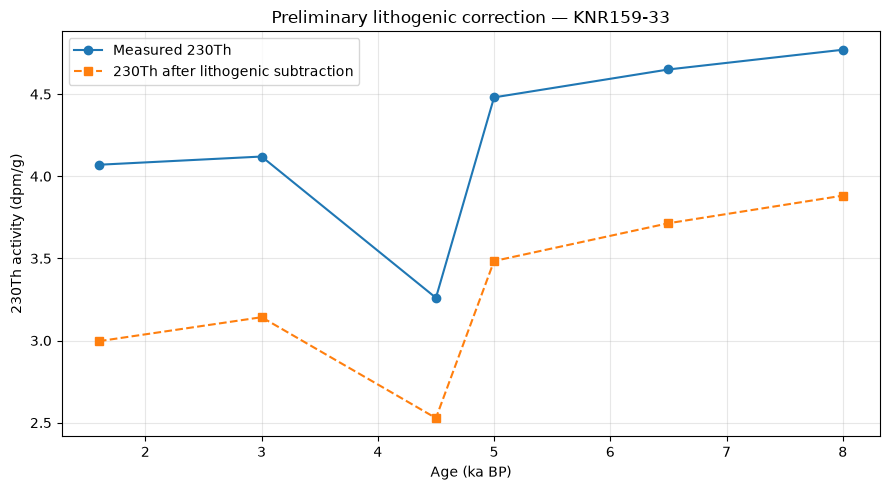

In [30]:
event_id = "KNR159-33"

core = (
    calc_df[calc_df["event_id"] == event_id]
    .sort_values("age_ka_bp")
)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    core["age_ka_bp"],
    core["th230_dpm_g"],
    "o-",
    label="Measured 230Th"
)

ax.plot(
    core["age_ka_bp"],
    core["th230_after_lith_dpm_g"],
    "s--",
    label="230Th after lithogenic subtraction"
)

ax.set_xlabel("Age (ka BP)")
ax.set_ylabel("230Th activity (dpm/g)")
ax.set_title(f"Preliminary lithogenic correction — {event_id}")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [31]:
calculation_file = output_dir / "lippold_2024_preliminary_th230.csv"

calc_df.to_csv(calculation_file, index=False)

print("Saved:", calculation_file.resolve())

Saved: /Users/farabiisa/Desktop/Thesis_Work/03_Data/Processed/lippold_2024_preliminary_th230.csv


In [32]:
display(
    calc_df[
        [
            "sample_id",
            "event_id",
            "age_ka_bp",
            "th230_dpm_g",
            "th232_dpm_g",
            "u238_dpm_g",
            "th230_after_lith_dpm_g"
        ]
    ].head(10)
)

print("238U activity range:")
print(calc_df["u238_dpm_g"].describe())

,sample_id,event_id,age_ka_bp,th230_dpm_g,th232_dpm_g,u238_dpm_g,th230_after_lith_dpm_g
0,LIPPOLD2024_0001,AII107-117GGC,5.6,8.61,0.46,0.34,8.334
1,LIPPOLD2024_0002,AII107-117GGC,6.1,9.54,0.55,0.39,9.210
2,LIPPOLD2024_0003,AII107-117GGC,6.9,9.28,0.52,0.37,8.968
3,LIPPOLD2024_0004,AII107-117GGC,7.7,8.72,0.50,0.35,8.420
4,LIPPOLD2024_0005,GeoB18530-1,0.0,2.12,1.95,1.21,0.950
5,LIPPOLD2024_0006,GeoB18530-1,2.6,2.27,2.18,1.60,0.962
6,LIPPOLD2024_0007,GeoB18530-1,5.5,2.29,2.33,1.65,0.892
7,LIPPOLD2024_0008,GeoB18530-1,7.6,2.14,2.29,1.59,0.766
8,LIPPOLD2024_0009,306-U1313C,2.1,5.86,0.45,0.26,5.590
9,LIPPOLD2024_0010,306-U1313C,3.4,5.82,0.47,0.26,5.538


238U activity range:
count    44.000000
mean      0.666136
std       0.443476
min       0.240000
25%       0.290000
50%       0.380000
75%       1.012500
max       1.650000
Name: u238_dpm_g, dtype: float64
